<a href="https://colab.research.google.com/github/raghavendra-s/Diabetes-Disease-Prediction/blob/main/raghavendra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Project Directory Structure Setup
We'll structure our project into clean, modular directories and files representing datasets, processing logic, modeling, visualizations, and static assets.

In [ ]:
import os

# Create project folders
dirs = ['data', 'src', 'models', 'plots']
for d in dirs:
    os.makedirs(d, exist_ok=True)
    print(f"Directory '{d}' created or already exists.")

Directory 'data' created or already exists.
Directory 'src' created or already exists.
Directory 'models' created or already exists.
Directory 'plots' created or already exists.


### 2. Dataset Integration
Since the file is hosted on Kaggle and various online sources, we will pull the authentic Pima Indians Diabetes Dataset directly from a stable raw repository URL and save it as `data/diabetes.csv`.

In [ ]:
import urllib.request
import pandas as pd

# URL to the official Pima Indians Diabetes Dataset (Raw on GitHub)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
csv_path = "data/diabetes.csv"

# Define proper header columns
columns = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

try:
    # Download the file
    urllib.request.urlretrieve(url, csv_path)
    # Load and save with headers
    df = pd.read_csv(csv_path, header=None, names=columns)
    df.to_csv(csv_path, index=False)
    print(f"Successfully downloaded and stored dataset at {csv_path}")
    print(f"Dataset shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"An error occurred during dataset acquisition: {e}")

Successfully downloaded and stored dataset at data/diabetes.csv
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 3. Exploratory Data Analysis & Visualization
We will write a specialized analysis script and output key charts. We ensure invalid zero values (for Glucose, BloodPressure, SkinThickness, Insulin, and BMI) are identified, and we'll visualize demographics and feature correlations.

In [ ]:
%%writefile src/eda.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import os

def run_eda(csv_path='data/diabetes.csv'):
    df = pd.read_csv(csv_path)

    print("=== Basic Dataset Information ===")
    print(f"Total records (Rows): {df.shape[0]}")
    print(f"Total features (Columns): {df.shape[1]}")
    print("\n--- Feature Data Types ---")
    print(df.dtypes)
    print("\n--- Statistical Summary ---")
    print(df.describe())

    # Check for actual duplicate records
    duplicates = df.duplicated().sum()
    print(f"\nDuplicate Records: {duplicates}")

    # Analyze columns where zero is an invalid measurement
    zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
    print("\n--- Missing Value Analysis (represented by 0 values) ---")
    for col in zero_cols:
        zero_count = (df[col] == 0).sum()
        percentage = (zero_count / len(df)) * 100
        print(f"{col}: {zero_count} zero values ({percentage:.2f}% of data)")

    # Create directory for visualizations
    os.makedirs('plots', exist_ok=True)

    # Visualization 1: Pie Chart of Outcomes
    plt.figure(figsize=(6, 6))
    outcome_counts = df['Outcome'].value_counts()
    plt.pie(outcome_counts, labels=['Non-Diabetes', 'Diabetes'], autopct='%1.1f%%', colors=['#4CAF50', '#FF5722'], startangle=90)
    plt.title('Diabetes Patient Distribution')
    plt.savefig('plots/outcome_distribution.png', bbox_inches='tight')
    plt.close()

    # Visualization 2: Correlation Heatmap
    plt.figure(figsize=(10, 8))
    # Replace 0s temporarily to compute meaningful correlation with targets
    temp_df = df.copy()
    for col in zero_cols:
        temp_df[col] = temp_df[col].replace(0, np.nan)
    sns.heatmap(temp_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Feature Correlation Heatmap (Zero-Corrected)')
    plt.savefig('plots/correlation_heatmap.png', bbox_inches='tight')
    plt.close()

    # Visualization 3: BMI & Glucose Joint Distribution
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=temp_df, x='BMI', y='Glucose', hue='Outcome', palette={0: '#4CAF50', 1: '#FF5722'}, alpha=0.7)
    plt.title('Glucose vs BMI by Diabetes Outcome')
    plt.savefig('plots/glucose_vs_bmi.png', bbox_inches='tight')
    plt.close()

    print("\nEDA calculations completed! Static plots saved under 'plots/'.")
    return temp_df

if __name__ == '__main__':
    run_eda()

Writing src/eda.py


=== Basic Dataset Information ===
Total records (Rows): 768
Total features (Columns): 9

--- Feature Data Types ---
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

--- Statistical Summary ---
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000 

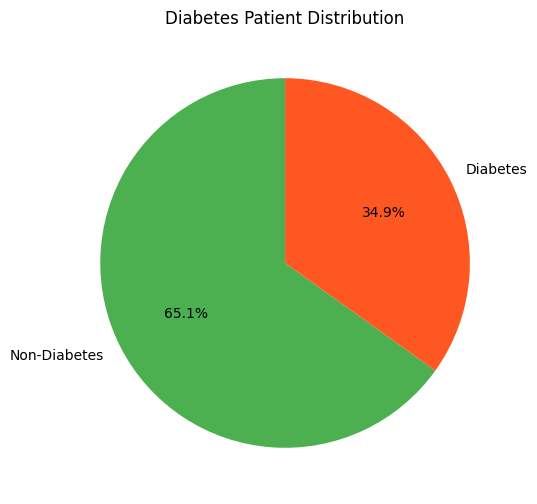

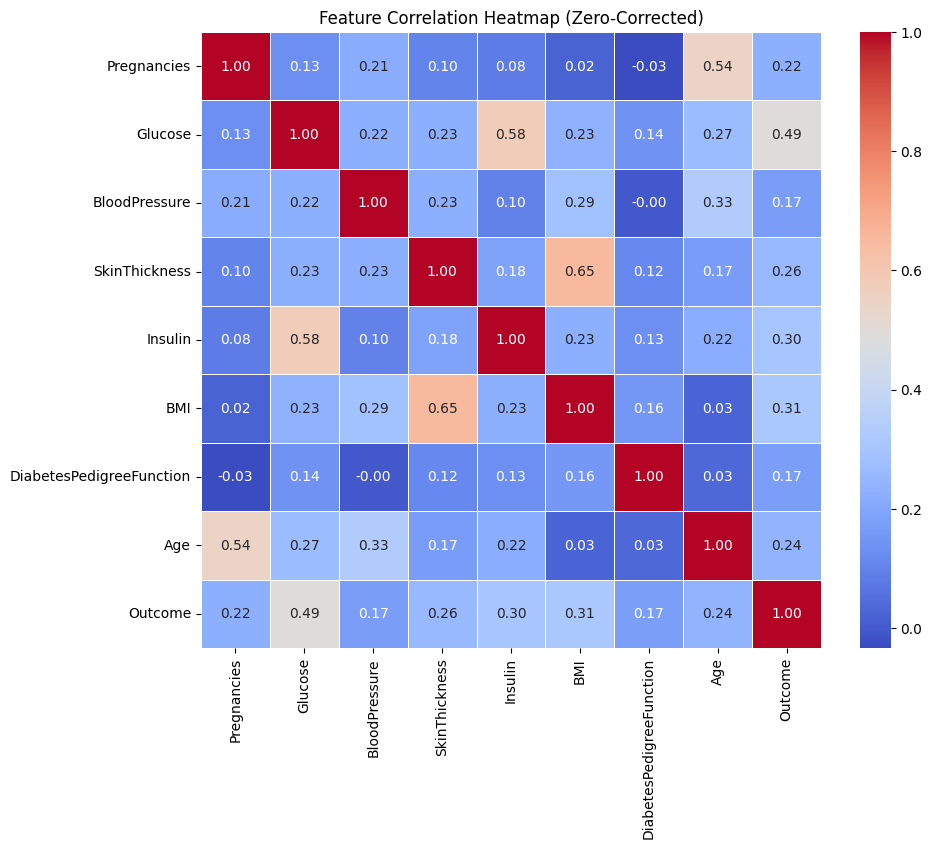

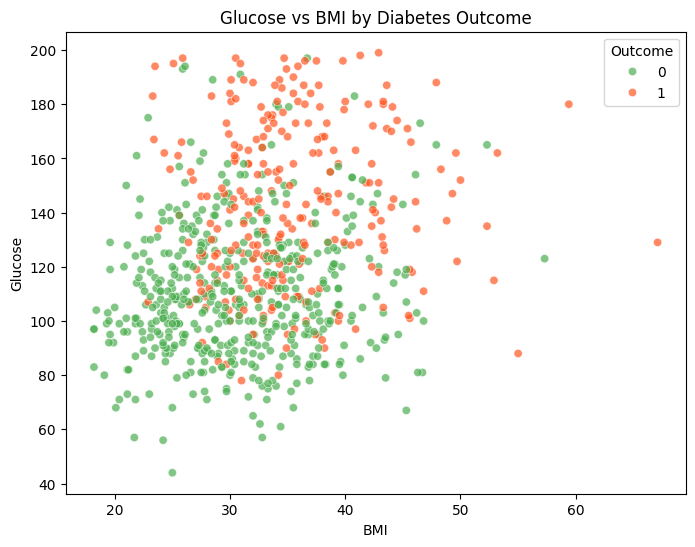

In [ ]:
# Run the EDA script to test output and display visualizations inline
from src.eda import run_eda
from IPython.display import Image, display

corrected_df = run_eda()

print("\n--- Visualizations Generated ---")
display(Image(filename='plots/outcome_distribution.png'))
display(Image(filename='plots/correlation_heatmap.png'))
display(Image(filename='plots/glucose_vs_bmi.png'))

### Enhanced Dataset Visualization (Scrollable and Cleanly Aligned)

In [ ]:
import pandas as pd
from IPython.display import display, HTML

# Load the dataset
df_raw = pd.read_csv('data/diabetes.csv')

# Style table dynamically to ensure perfect cell alignment, padding, and responsive horizontal scrolling
html_style = """
<style>
    .table-container {
        overflow-x: auto;
        width: 100%;
        margin: 20px 0;
        border-radius: 8px;
        box-shadow: 0 4px 6px rgba(0,0,0,0.1);
    }
    .clean-table {
        width: 100%;
        border-collapse: collapse;
        font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
        background-color: #ffffff;
        min-width: 900px;
    }
    .clean-table th {
        background-color: #1B5E20;
        color: white;
        padding: 12px 16px;
        text-align: center;
        font-size: 14px;
        font-weight: 600;
        white-space: nowrap;
        border-bottom: 3px solid #124116;
    }
    .clean-table td {
        padding: 10px 16px;
        text-align: center;
        border-bottom: 1px solid #e0e0e0;
        color: #333333;
        font-size: 13.5px;
        white-space: nowrap;
    }
    .clean-table tr:nth-child(even) {
        background-color: #f9f9f9;
    }
    .clean-table tr:hover {
        background-color: #f1f8e9;
    }
</style>
"""

# Generate HTML representation
table_html = f"""
<div class="table-container">
    <table class="clean-table">
        <thead>
            <tr>
                {''.join(f'<th>{col}</th>' for col in df_raw.columns)}
            </tr>
        </thead>
        <tbody>
"""

for idx, row in df_raw.head(15).iterrows():
    table_html += "            <tr>\n"
    for col in df_raw.columns:
        val = row[col]
        formatted_val = f"{val:.3f}" if isinstance(val, float) else str(val)
        table_html += f"                <td>{formatted_val}</td>\n"
    table_html += "            </tr>\n"

table_html += """
        </tbody>
    </table>
</div>
"""

display(HTML(html_style + table_html))

Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
6.000,148.000,72.000,35.000,0.000,33.600,0.627,50.000,1.000
1.000,85.000,66.000,29.000,0.000,26.600,0.351,31.000,0.000
8.000,183.000,64.000,0.000,0.000,23.300,0.672,32.000,1.000
1.000,89.000,66.000,23.000,94.000,28.100,0.167,21.000,0.000
0.000,137.000,40.000,35.000,168.000,43.100,2.288,33.000,1.000
5.000,116.000,74.000,0.000,0.000,25.600,0.201,30.000,0.000
3.000,78.000,50.000,32.000,88.000,31.000,0.248,26.000,1.000
10.000,115.000,0.000,0.000,0.000,35.300,0.134,29.000,0.000
2.000,197.000,70.000,45.000,543.000,30.500,0.158,53.000,1.000
8.000,125.000,96.000,0.000,0.000,0.000,0.232,54.000,1.000


### Robust Visualization Dashboard (Separated Container Layout)
We will now generate the six specific visualizations in the exact requested order and wrap each cleanly inside its own padded card layout to prevent overlaps.


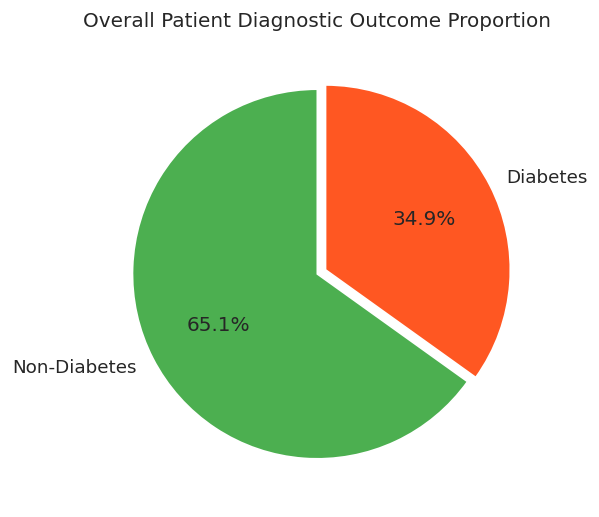


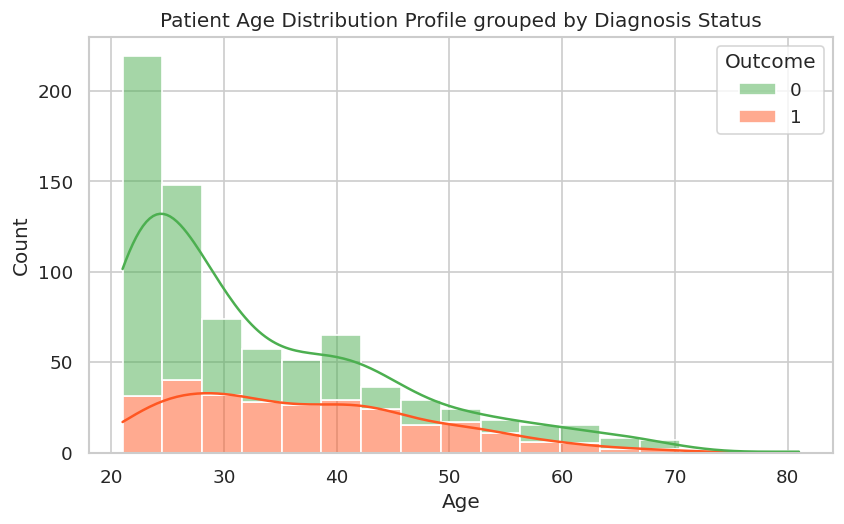


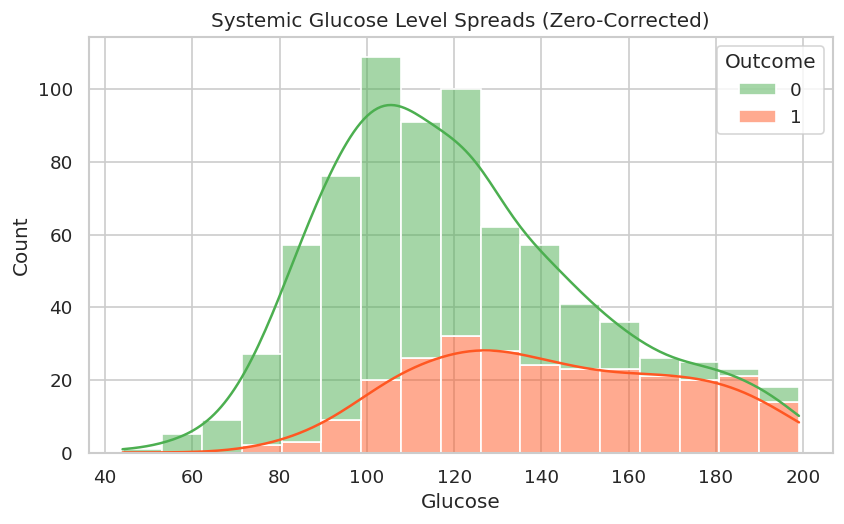


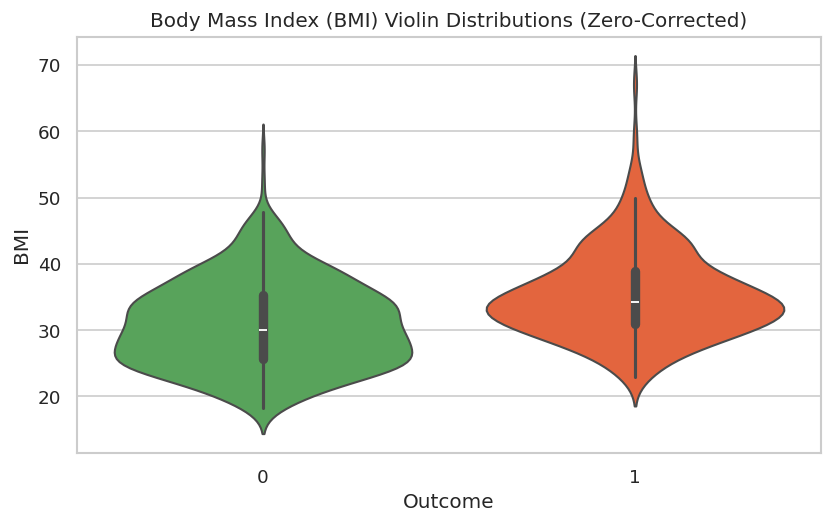


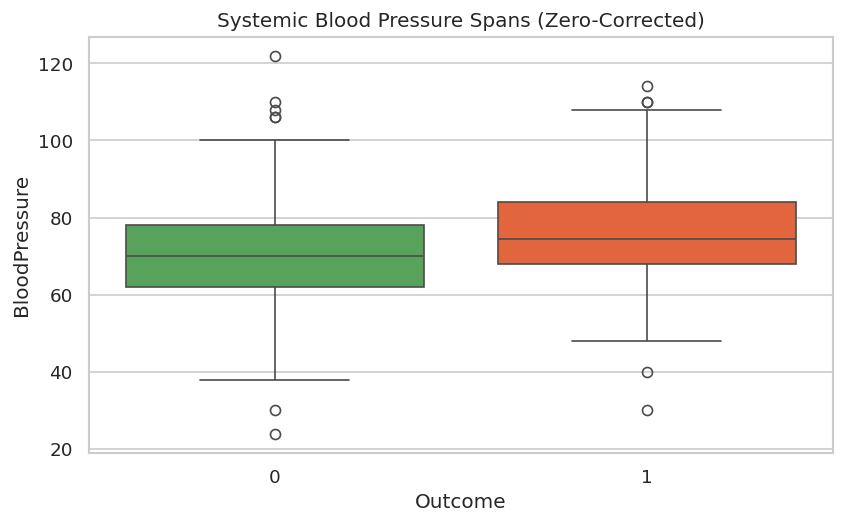


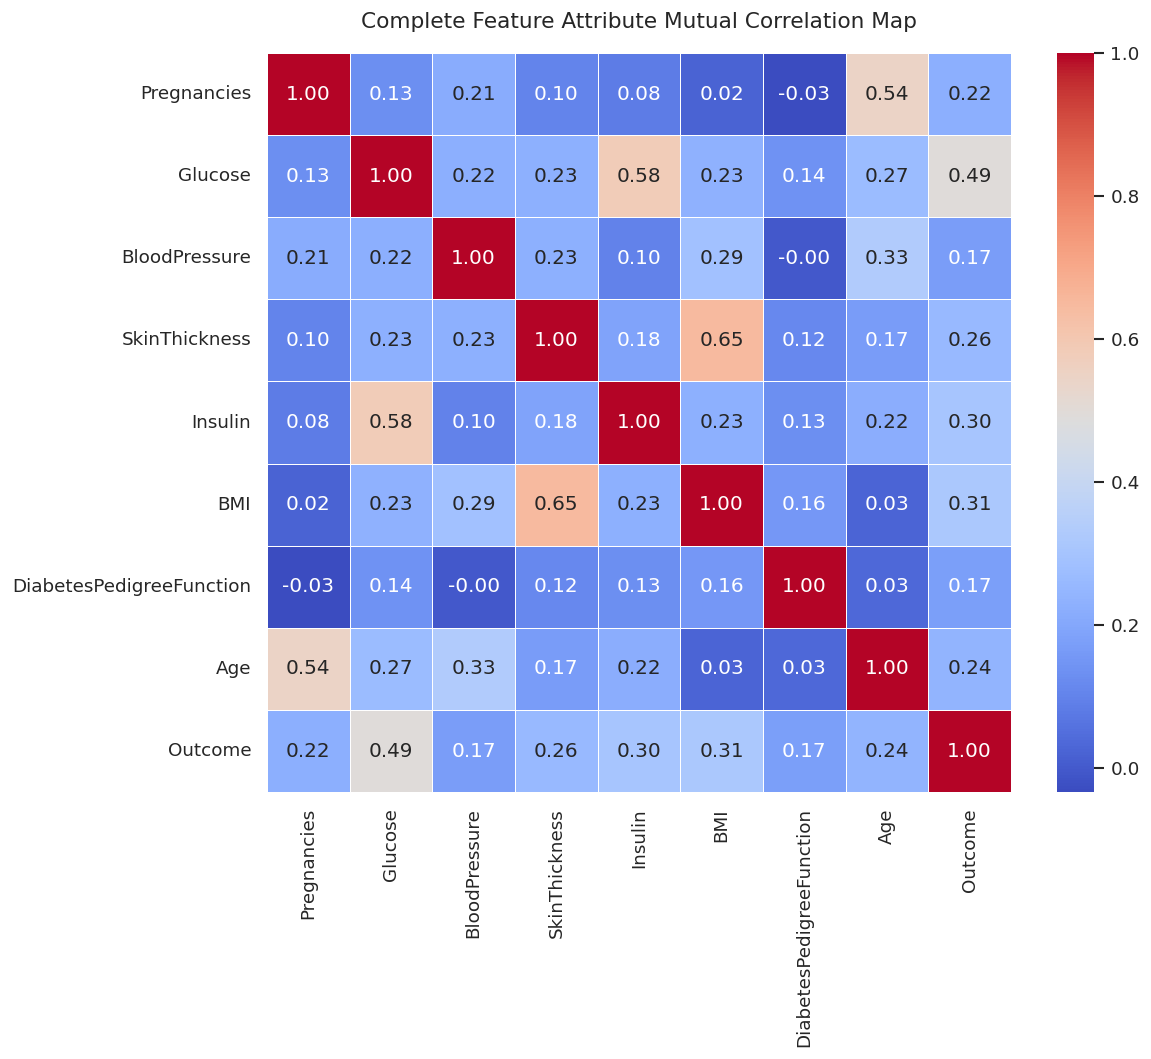

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import base64
from IPython.display import display, HTML

os.makedirs('plots', exist_ok=True)
sns.set_theme(style="whitegrid")

# Prepare zero-corrected data for meaningful distributions
df_temp = df_raw.copy()
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in zero_cols:
    df_temp[col] = df_temp[col].replace(0, np.nan)

# Setup styling and rendering helper using robust inline Base64 encoding
def save_and_wrap_chart(fig, filename, title):
    filepath = f"plots/{filename}"
    fig.savefig(filepath, dpi=120, bbox_inches='tight')
    plt.close(fig)

    # Verify file is written successfully and encode to base64 to avoid local filesystem loading failures in browser
    if os.path.exists(filepath):
        with open(filepath, "rb") as img_file:
            encoded_string = base64.b64encode(img_file.read()).decode('utf-8')
        img_src = f"data:image/png;base64,{encoded_string}"
    else:
        img_src = ""
        error_message = f"<div style='color: #D32F2F; padding: 10px; font-weight: bold;'>Error: Visual chart image file could not be generated at {filepath}.</div>"

    # Generate isolated responsive display card with inline styling
    card_html = f"""
    <div style="
        background: #ffffff;
        border: 1px solid #e2e8f0;
        border-radius: 12px;
        box-shadow: 0 4px 12px rgba(0,0,0,0.05);
        padding: 24px;
        margin: 25px 0;
        max-width: 900px;
    ">
        <h3 style="color: #2E7D32; font-family: 'Segoe UI', Tahoma; margin-top: 0; margin-bottom: 15px; border-bottom: 2px solid #E8F5E9; padding-bottom: 8px;">{title}</h3>
        <div style="text-align: center;">
            {f'<img src="{img_src}" style="max-width: 100%; height: auto; border-radius: 6px;" />' if img_src else error_message}
        </div>
    </div>
    """
    display(HTML(card_html))

# 1. Diabetes vs Non-Diabetes Pie Chart
fig, ax = plt.subplots(figsize=(6, 5))
outcome_counts = df_raw['Outcome'].value_counts()
ax.pie(outcome_counts, labels=['Non-Diabetes', 'Diabetes'], autopct='%1.1f%%', colors=['#4CAF50', '#FF5722'], startangle=90, explode=(0, 0.05))
ax.set_title('Overall Patient Diagnostic Outcome Proportion', fontsize=12, pad=10)
save_and_wrap_chart(fig, 'dash_pie_chart.png', '1. Diabetes Patient Distribution Proportion')

# 2. Age Distribution Histogram
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='Age', hue='Outcome', multiple='stack', palette={0: '#4CAF50', 1: '#FF5722'}, kde=True, ax=ax)
ax.set_title('Patient Age Distribution Profile grouped by Diagnosis Status', fontsize=12)
save_and_wrap_chart(fig, 'dash_age_hist.png', '2. Patient Age Distribution Profile')

# 3. Glucose Distribution Histogram
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_temp, x='Glucose', hue='Outcome', multiple='stack', palette={0: '#4CAF50', 1: '#FF5722'}, kde=True, ax=ax)
ax.set_title('Systemic Glucose Level Spreads (Zero-Corrected)', fontsize=12)
save_and_wrap_chart(fig, 'dash_glucose_hist.png', '3. Glucose Concentration Distribution')

# 4. BMI Distribution Chart
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=df_temp, x='Outcome', y='BMI', palette={0: '#4CAF50', 1: '#FF5722'}, ax=ax, hue='Outcome', legend=False)
ax.set_title('Body Mass Index (BMI) Violin Distributions (Zero-Corrected)', fontsize=12)
save_and_wrap_chart(fig, 'dash_bmi_violin.png', '4. Body Mass Index (BMI) Density Comparison')

# 5. Blood Pressure Analysis
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_temp, x='Outcome', y='BloodPressure', palette={0: '#4CAF50', 1: '#FF5722'}, ax=ax, hue='Outcome', legend=False)
ax.set_title('Systemic Blood Pressure Spans (Zero-Corrected)', fontsize=12)
save_and_wrap_chart(fig, 'dash_bp_box.png', '5. Diastolic Blood Pressure Boxplot Analysis')

# 6. Feature Correlation Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df_temp.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Complete Feature Attribute Mutual Correlation Map', fontsize=13, pad=15)
save_and_wrap_chart(fig, 'dash_correlation_map.png', '6. Comprehensive Feature Inter-Correlation Matrix')

### 4. Data Preprocessing & Pipeline Construction
We'll handle zero-values using median imputation based on the target outcome to avoid data leakage. Then, we will save the preprocessing configuration and scaler.

In [ ]:
%%writefile src/preprocessing.py
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib
import os

def preprocess_data(csv_path='data/diabetes.csv'):
    df = pd.read_csv(csv_path)

    # Distinguish target and features
    X = df.drop(columns=['Outcome'])
    y = df['Outcome']

    # Split train and test set to avoid leakage during scale/imputation fitting
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Columns where zero is invalid and needs imputation
    impute_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

    # Convert 0 to NaN for those specific columns
    X_train_imputed = X_train.copy()
    X_test_imputed = X_test.copy()

    for col in impute_cols:
        X_train_imputed[col] = X_train_imputed[col].replace(0, np.nan)
        X_test_imputed[col] = X_test_imputed[col].replace(0, np.nan)

    # Learn training median values per outcome group
    imputation_values = {}
    for col in impute_cols:
        # Compute median grouped by training outcomes
        medians = X_train_imputed.groupby(y_train)[col].median()
        imputation_values[col] = medians.to_dict()

        # Impute training features
        for outcome in [0, 1]:
            idx_train = (y_train == outcome)
            X_train_imputed.loc[idx_train, col] = X_train_imputed.loc[idx_train, col].fillna(medians[outcome])

            idx_test = (y_test == outcome)
            X_test_imputed.loc[idx_test, col] = X_test_imputed.loc[idx_test, col].fillna(medians[outcome])

    # Standard scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_imputed)
    X_test_scaled = scaler.transform(X_test_imputed)

    # Save scaler and imputation mapping for real-time app inference
    os.makedirs('models', exist_ok=True)
    joblib.dump(scaler, 'models/scaler.pkl')
    joblib.dump(imputation_values, 'models/imputation_values.pkl')

    # Package as structured datasets
    train_dataset = pd.DataFrame(X_train_scaled, columns=X.columns)
    train_dataset['Outcome'] = y_train.values
    test_dataset = pd.DataFrame(X_test_scaled, columns=X.columns)
    test_dataset['Outcome'] = y_test.values

    train_dataset.to_csv('data/train_processed.csv', index=False)
    test_dataset.to_csv('data/test_processed.csv', index=False)

    print("Preprocessing pipeline successfully built. Datasets and assets saved to data/ and models/ directories.")
    return X_train_scaled, X_test_scaled, y_train, y_test

if __name__ == '__main__':
    preprocess_data()

Writing src/preprocessing.py


In [ ]:
from src.preprocessing import preprocess_data
X_train, X_test, y_train, y_test = preprocess_data()

Preprocessing pipeline successfully built. Datasets and assets saved to data/ and models/ directories.


### 5. Training, Evaluation and Confusion Matrix Generation
Let's train the 5 core machine learning classification models (Logistic Regression, Decision Tree, Random Forest, SVM, KNN), run predictions on our test sets, extract and display TP, TN, FP, FN metrics, and save the best model.

In [ ]:
%%writefile src/model_training.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
import joblib
import os

def train_and_evaluate(X_train, X_test, y_train, y_test):
    models = {
        'Logistic Regression': LogisticRegression(random_state=42),
        'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=5),
        'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
        'Support Vector Machine': SVC(probability=True, random_state=42),
        'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
    }

    results = {}
    best_f1 = -1
    best_model_name = None
    best_model_obj = None

    for name, model in models.items():
        # Train
        model.fit(X_train, y_train)
        # Predict
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

        results[name] = {
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'preds': y_pred,
            'probas': y_proba
        }

        # Visualizing confusion matrix
        plt.figure(figsize=(5, 4))
        sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Predicted 0', 'Predicted 1'],
                    yticklabels=['Actual 0', 'Actual 1'])
        plt.title(f'Confusion Matrix - {name}')
        plt.savefig(f'plots/confusion_{name.lower().replace(" ", "_")}.png', bbox_inches='tight')
        plt.close()

        if f1 > best_f1:
            best_f1 = f1
            best_model_name = name
            best_model_obj = model

    # Save overall performance
    perf_df = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'TN', 'FP', 'FN', 'TP']]
    perf_df.to_csv('plots/model_comparison.csv')

    # Save Best Model
    joblib.dump(best_model_obj, 'models/best_model.pkl')
    with open('models/best_model_info.txt', 'w') as f:
        f.write(best_model_name)

    # Generate a dedicated best-model plot
    tn, fp, fn, tp = results[best_model_name]['TN'], results[best_model_name]['FP'], results[best_model_name]['FN'], results[best_model_name]['TP']
    plt.figure(figsize=(6, 5))
    sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cmap='Greens',
                xticklabels=['Non-Diabetes', 'Diabetes'],
                yticklabels=['Non-Diabetes', 'Diabetes'])
    plt.title(f'Best Model Matrix: {best_model_name}')
    plt.savefig('plots/best_model_confusion_matrix.png', bbox_inches='tight')
    plt.close()

    print(f"\nBest performing model determined: {best_model_name} (F1: {best_f1:.4f})")
    return perf_df, results, best_model_name

if __name__ == '__main__':
    import pandas as pd
    train_p = pd.read_csv('data/train_processed.csv')
    test_p = pd.read_csv('data/test_processed.csv')
    X_tr = train_p.drop(columns=['Outcome']).values
    y_tr = train_p['Outcome'].values
    X_te = test_p.drop(columns=['Outcome']).values
    y_te = test_p['Outcome'].values
    train_and_evaluate(X_tr, X_te, y_tr, y_te)

Writing src/model_training.py


In [ ]:
from src.model_training import train_and_evaluate
metrics_df, detailed_results, best_model_name = train_and_evaluate(X_train, X_test, y_train, y_test)

print("=== Complete Model Evaluation & Analysis Matrix ===")
display(metrics_df)


Best performing model determined: Random Forest (F1: 0.8113)
=== Complete Model Evaluation & Analysis Matrix ===


,Accuracy,Precision,Recall,F1-Score,TN,FP,FN,TP
Logistic Regression,0.707792,0.588235,0.555556,0.571429,79,21,24,30
Decision Tree,0.818182,0.75,0.722222,0.735849,87,13,15,39
Random Forest,0.87013,0.826923,0.796296,0.811321,91,9,11,43
Support Vector Machine,0.837662,0.763636,0.777778,0.770642,87,13,12,42
K-Nearest Neighbors,0.824675,0.754717,0.740741,0.747664,87,13,14,40


In [ ]:
import pandas as pd
from IPython.display import display, HTML

# Read the raw performance metrics
perf_df = pd.read_csv('plots/model_comparison.csv', index_col=0)

# Format metrics gracefully to percentages
formatted_df = perf_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    formatted_df[col] = formatted_df[col].map(lambda x: f"{x * 100:.2f}%")

# Reset index to treat Model Name as a normal column
formatted_df = formatted_df.reset_index().rename(columns={'index': 'Model Name'})

# Rearrange columns to match requirements
column_order = ['Model Name', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'TN', 'FP', 'FN', 'TP']
formatted_df = formatted_df[column_order]

# Build responsive styled HTML table with perfect column alignments
html_table = """
<div style="overflow-x: auto; width: 100%; margin: 20px 0;">
    <table style="width: 100%; min-width: 800px; border-collapse: collapse; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 6px rgba(0,0,0,0.1); border-radius: 8px; overflow: hidden;">
        <thead>
            <tr style="background-color: #2E7D32; color: white;">
                <th style="padding: 12px 15px; text-align: left; font-weight: 600;">Model Name</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">Accuracy</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">Precision</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">Recall</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">F1-Score</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">TN</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">FP</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">FN</th>
                <th style="padding: 12px 15px; text-align: center; font-weight: 600;">TP</th>
            </tr>
        </thead>
        <tbody>
"""

for idx, row in formatted_df.iterrows():
    bg_color = "#f9f9f9" if idx % 2 == 0 else "#ffffff"
    html_table += f"""
            <tr style="background-color: {bg_color}; border-bottom: 1px solid #dddddd; transition: background 0.2s;">
                <td style="padding: 12px 15px; text-align: left; font-weight: bold; color: #333;">{row['Model Name']}</td>
                <td style="padding: 12px 15px; text-align: center; color: #555;">{row['Accuracy']}</td>
                <td style="padding: 12px 15px; text-align: center; color: #555;">{row['Precision']}</td>
                <td style="padding: 12px 15px; text-align: center; color: #555;">{row['Recall']}</td>
                <td style="padding: 12px 15px; text-align: center; color: #555;">{row['F1-Score']}</td>
                <td style="padding: 12px 15px; text-align: center; font-weight: 500; color: #2C3E50;">{row['TN']}</td>
                <td style="padding: 12px 15px; text-align: center; font-weight: 500; color: #C0392B;">{row['FP']}</td>
                <td style="padding: 12px 15px; text-align: center; font-weight: 500; color: #D35400;">{row['FN']}</td>
                <td style="padding: 12px 15px; text-align: center; font-weight: 500; color: #27AE60;">{row['TP']}</td>
            </tr>
    """

html_table += """
        </tbody>
    </table>
</div>
"""

display(HTML(html_table))

Model Name,Accuracy,Precision,Recall,F1-Score,TN,FP,FN,TP
Logistic Regression,70.78%,58.82%,55.56%,57.14%,79,21,24,30
Decision Tree,81.82%,75.00%,72.22%,73.58%,87,13,15,39
Random Forest,87.01%,82.69%,79.63%,81.13%,91,9,11,43
Support Vector Machine,83.77%,76.36%,77.78%,77.06%,87,13,12,42
K-Nearest Neighbors,82.47%,75.47%,74.07%,74.77%,87,13,14,40


### 6. Display Best Model Confusion Matrix
Here is the actual confusion matrix plotted for the best performing machine learning classifier model.

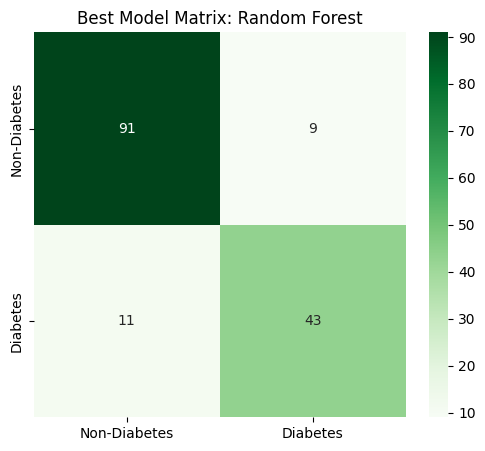

In [ ]:
display(Image(filename='plots/best_model_confusion_matrix.png'))

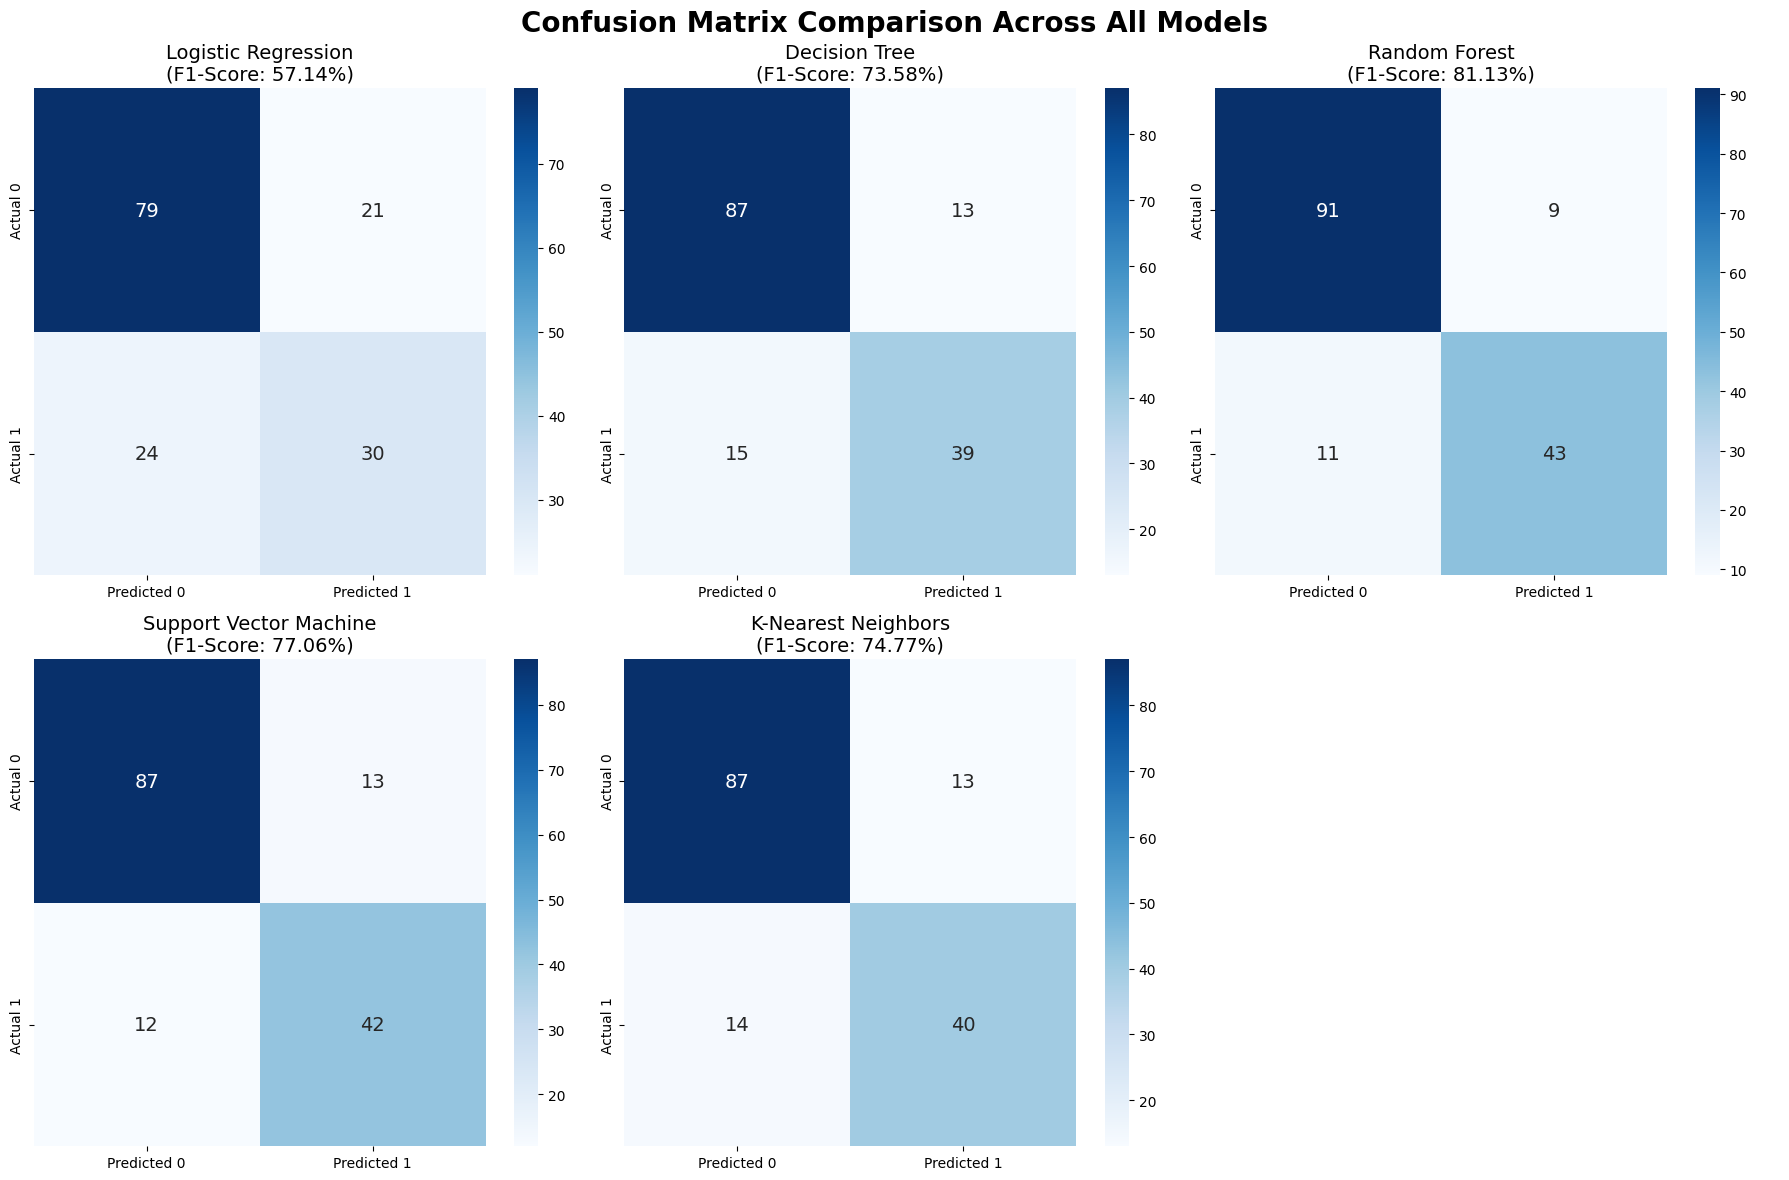

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Find all generated confusion matrix images
model_names = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Support Vector Machine',
    'K-Nearest Neighbors'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for idx, name in enumerate(model_names):
    res = detailed_results[name]
    tn, fp, fn, tp = res['TN'], res['FP'], res['FN'], res['TP']

    sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['Actual 0', 'Actual 1'],
                annot_kws={'size': 14})
    axes[idx].set_title(f'{name}\n(F1-Score: {res["F1-Score"]:.2%})', fontsize=14)

# Disable the last empty subplot (6th one)
axes[5].axis('off')

plt.suptitle('Confusion Matrix Comparison Across All Models', fontsize=20, weight='bold', y=0.98)
plt.tight_layout()
plt.savefig('plots/all_models_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

### 7. Core Prediction Logic with Input Validation
We'll define the production inference script that handles new input vectors, loads the preprocessing metadata/scaler, ensures robust data integrity checks, and serves precise inferences with raw calculated probabilities.

In [ ]:
%%writefile src/prediction.py
import numpy as np
import joblib

def predict_diabetes(pregnancies, glucose, bp, skin, insulin, bmi, dpf, age):
    # 1. Input Validation Checks
    inputs = [pregnancies, glucose, bp, skin, insulin, bmi, dpf, age]
    if any(val is None or val < 0 for val in inputs):
        return {"error": "Invalid input: All values must be non-negative."}

    # 2. Loading Pipeline Assets
    scaler = joblib.load('models/scaler.pkl')
    imputation_values = joblib.load('models/imputation_values.pkl')
    best_model = joblib.load('models/best_model.pkl')

    # 3. Apply Imputations mimicking preprocessed state if zeros exist on critical features
    # We utilize general median mapping fallback to be robust
    impute_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
    input_dict = {
        'Pregnancies': pregnancies,
        'Glucose': glucose,
        'BloodPressure': bp,
        'SkinThickness': skin,
        'Insulin': insulin,
        'BMI': bmi,
        'DiabetesPedigreeFunction': dpf,
        'Age': age
    }

    for col in impute_cols:
        if input_dict[col] == 0:
            # Take average of positive outcomes medians for dynamic imputation
            input_dict[col] = (imputation_values[col][0] + imputation_values[col][1]) / 2

    # 4. Form Feature Vector & Apply Scaling
    feature_vector = np.array([
        input_dict['Pregnancies'],
        input_dict['Glucose'],
        input_dict['BloodPressure'],
        input_dict['SkinThickness'],
        input_dict['Insulin'],
        input_dict['BMI'],
        input_dict['DiabetesPedigreeFunction'],
        input_dict['Age']
    ]).reshape(1, -1)

    scaled_vector = scaler.transform(feature_vector)

    # 5. Model Inference
    prediction = int(best_model.predict(scaled_vector)[0])
    probability = float(best_model.predict_proba(scaled_vector)[0][1]) if hasattr(best_model, "predict_proba") else (1.0 if prediction == 1 else 0.0)

    return {
        "prediction": "Likely to have Diabetes" if prediction == 1 else "Unlikely to have Diabetes",
        "probability": f"{probability * 100:.2f}%",
        "disclaimer": "Disclaimer: This prediction is for educational and illustrative purposes only and should not be used as professional medical advice."
    }

Writing src/prediction.py


In [ ]:
# Test the inference logic with sample input data
from src.prediction import predict_diabetes

sample_patient_prediction = predict_diabetes(
    pregnancies=1,
    glucose=140,
    bp=74,
    skin=25,
    insulin=110,
    bmi=28.4,
    dpf=0.55,
    age=32
)

import json
print(json.dumps(sample_patient_prediction, indent=2))

{
  "prediction": "Unlikely to have Diabetes",
  "probability": "19.00%",
  "disclaimer": "Disclaimer: This prediction is for educational and illustrative purposes only and should not be used as professional medical advice."
}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
